# 💳 Credit Risk Assessment — Loan Default Prediction

Predict whether a loan applicant is **high-risk** (likely to default) or **low-risk**, comparing three machine learning models optimized for class imbalance.

### 📋 Pipeline
1. **Cleaning:** Median-impute employment length, drop `loan_int_rate` (~10% missing values), remove duplicates & outliers.
2. **Feature Engineering:** Recompute `loan_percent_income` relative to updated income values.
3. **Encoding:** Binary mapping (default history), ordinal encoding (loan grade A→G), and one-hot encoding (home ownership, loan intent).
4. **Split & Scale:** Stratified 80/20 train/test split followed by standard scaling on numerical features.
5. **Modeling & Imbalance Handling:** Baseline Logistic Regression, standard Random Forest, and cost-sensitive XGBoost using scaled class weights (`scale_pos_weight`).

### 🏆 Results (held-out test set, 6,453 applicants)

| Model | Accuracy | Recall (Class 1) | F1-Score (Class 1) |
|---|---|---|---|
| Logistic Regression | 86.1% | 55% | 63% |
| **Random Forest (200 trees)** | **93.7%** | 74% | 84% |
| **XGBoost (Cost-Sensitive)** | **92.0%** | **81%** | **82%** |

All seeds are fixed (`random_state=42`) to guarantee reproducible outputs.

The final model is deployed as an interactive **Streamlit** app → [GitHub repo]

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.decomposition import PCA
from sklearn.linear_model import Perceptron
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier


In [3]:
data = pd.read_csv("/content/credit_risk_dataset.csv")

In [4]:
data.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [5]:
data.shape

(32581, 12)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


# Data Preprocessing

## Handle missing values

In [7]:
data.isna().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [8]:
data['person_emp_length'] = data['person_emp_length'].fillna(data['person_emp_length'].median())

In [9]:
data = data.drop(['loan_int_rate'], axis=1)

In [10]:
data.isna().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_status,0
loan_percent_income,0
cb_person_default_on_file,0


## Handle duplicates

In [11]:
data = data.drop_duplicates()

## Handle outliers

In [12]:
data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32405.000000,3.240500e+04,32405.000000,32405.000000,32405.000000,32405.000000,32405.000000
mean,27.748125,6.609516e+04,4.769542,9594.201512,0.218732,0.170252,5.812344
std,6.354683,6.202414e+04,4.090647,6323.225445,0.413393,0.106820,4.059290
min,20.000000,4.000000e+03,0.000000,500.000000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,0.000000,0.150000,4.000000
75%,30.000000,7.938000e+04,7.000000,12250.000000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,1.000000,0.830000,30.000000


In [13]:
age_outliers = data[data['person_age'] > 100].shape[0]
income_outliers = data[data['person_income'] > 300000].shape[0]
emp_outliers = data[data['person_emp_length'] > 50].shape[0]

print("Outliers in person_age:", age_outliers)
print("Outliers in person_income:", income_outliers)
print("Outliers in person_emp_length:", emp_outliers)

Outliers in person_age: 5
Outliers in person_income: 137
Outliers in person_emp_length: 2


In [14]:
# Remove outliers for person_age > 100
data = data[data['person_age'] <= 100]

In [15]:
# Remove outliers for person_income > 300,000
data = data[data['person_income'] <= 300000]

In [16]:
# Remove outliers for employment length > 50 years
data = data[data['person_emp_length'] <= 50]

In [17]:
data['loan_percent_income'] = round(data['loan_amnt'] / data['person_income'], 2)

In [18]:
data.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,1,0.64,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,1,0.25,N,2


## Encode categorical variables

In [19]:
# 1) Binary Encoding
data['cb_person_default_on_file'] = data['cb_person_default_on_file'].map({'Y': 1, 'N': 0})

# 2) Ordinal Encoding for loan_grade (A < B < C < D < E < F < G)
grade_order = {'A':1, 'B':2, 'C':3, 'D':4, 'E':5, 'F':6, 'G':7}
data['loan_grade'] = data['loan_grade'].map(grade_order)

# 3) One-Hot Encoding for nominal categorical columns
data = pd.get_dummies(data, columns=['person_home_ownership', 'loan_intent'], drop_first=True)

In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32262 entries, 1 to 32580
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   person_age                   32262 non-null  int64  
 1   person_income                32262 non-null  int64  
 2   person_emp_length            32262 non-null  float64
 3   loan_grade                   32262 non-null  int64  
 4   loan_amnt                    32262 non-null  int64  
 5   loan_status                  32262 non-null  int64  
 6   loan_percent_income          32262 non-null  float64
 7   cb_person_default_on_file    32262 non-null  int64  
 8   cb_person_cred_hist_length   32262 non-null  int64  
 9   person_home_ownership_OTHER  32262 non-null  bool   
 10  person_home_ownership_OWN    32262 non-null  bool   
 11  person_home_ownership_RENT   32262 non-null  bool   
 12  loan_intent_EDUCATION        32262 non-null  bool   
 13  loan_intent_HOMEIMPRO

## Correlation Heatmap

In [21]:
corr = data.corr()
corr

,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
person_age,1.000000,0.105884,0.168414,0.011836,0.047268,-0.020252,-0.034158,0.004882,0.877468,-0.010570,-0.000884,-0.028279,-0.091963,0.076440,0.021514,0.033228,-0.013878
person_income,0.105884,1.000000,0.187866,-0.009116,0.405985,-0.220288,-0.341368,-0.013782,0.086829,0.003985,-0.063075,-0.267178,-0.010996,0.070971,-0.058342,0.004262,0.008141
person_emp_length,0.168414,0.187866,1.000000,-0.048068,0.110095,-0.085919,-0.054779,-0.030031,0.145559,-0.014341,0.023643,-0.231488,-0.037931,0.031869,-0.002091,0.008395,0.009987
loan_grade,0.011836,-0.009116,-0.048068,1.000000,0.145038,0.373752,0.129890,0.536554,0.013205,0.016947,-0.016856,0.120967,-0.008272,0.029141,0.001393,-0.006603,-0.010909
loan_amnt,0.047268,0.405985,0.110095,0.145038,1.000000,0.107214,0.587069,0.037996,0.038255,0.010806,-0.025823,-0.113765,-0.007918,0.042532,-0.024927,-0.001043,-0.000617
loan_status,-0.020252,-0.220288,-0.085919,0.373752,0.107214,1.000000,0.385999,0.179083,-0.014846,0.013475,-0.102303,0.238323,-0.055512,0.037078,0.055996,-0.021713,-0.078131
loan_percent_income,-0.034158,-0.341368,-0.054779,0.129890,0.587069,0.385999,1.000000,0.039792,-0.024417,0.012683,0.050041,0.113405,-0.003421,-0.016571,0.021330,-0.005327,-0.001300
cb_person_default_on_file,0.004882,-0.013782,-0.030031,0.536554,0.037996,0.179083,0.039792,1.000000,0.002470,0.013850,-0.003667,0.061921,-0.006196,0.015170,-0.003141,-0.003333,-0.003008
cb_person_cred_hist_length,0.877468,0.086829,0.145559,0.013205,0.038255,-0.014846,-0.024417,0.002470,1.000000,-0.008566,0.005076,-0.023606,-0.077728,0.058648,0.016799,0.034513,-0.008785
person_home_ownership_OTHER,-0.010570,0.003985,-0.014341,0.016947,0.010806,0.013475,0.012683,0.013850,-0.008566,1.000000,-0.016667,-0.057589,-0.006314,-0.000908,-0.003356,0.000549,0.009721


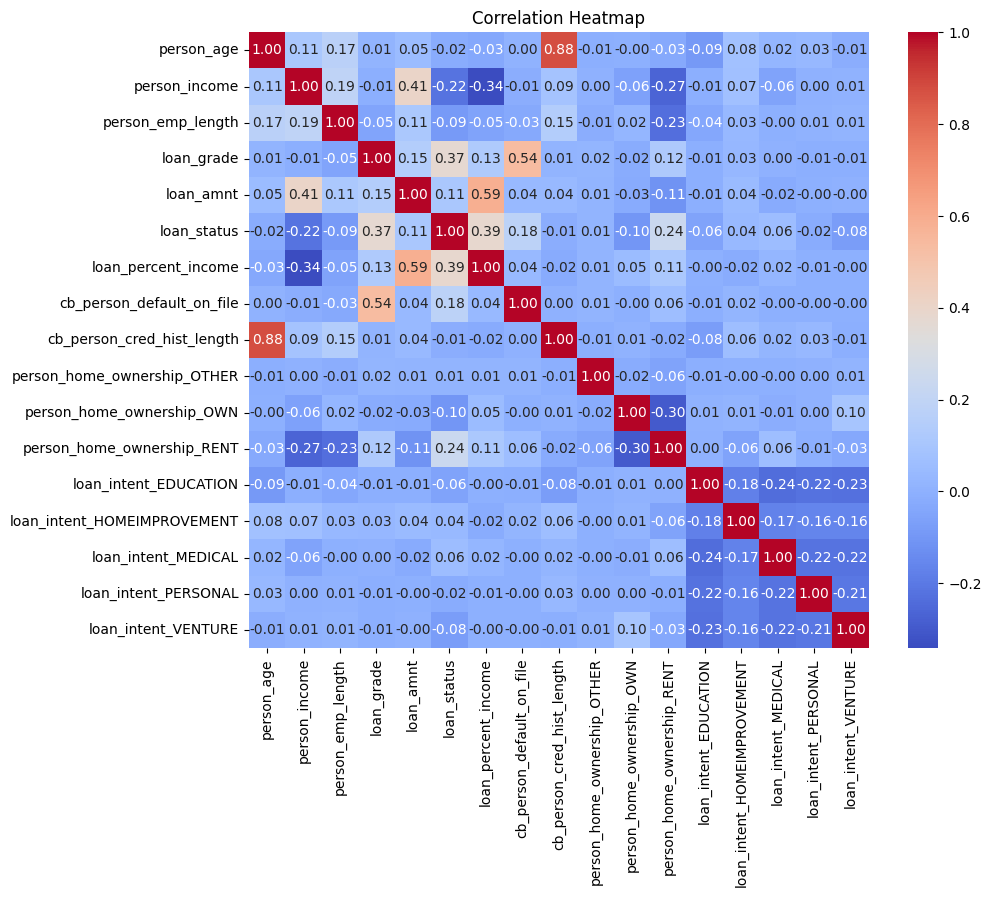

In [22]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


## Split the dataset

In [23]:
x = data.drop(['loan_status'], axis=1)
y = data['loan_status']

In [24]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

## Scale numeric features

In [25]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_percent_income', 'cb_person_cred_hist_length']

In [26]:
scaler = StandardScaler()

x_train[numeric_cols] = scaler.fit_transform(x_train[numeric_cols])
x_test[numeric_cols] = scaler.transform(x_test[numeric_cols])

In [27]:
feature_columns = x_train.columns.tolist()

# Classical ML Models

In [44]:
# Reduce to 2D for visualization
pca = PCA(n_components=2)
x_test_2d = pca.fit_transform(x_test)

# Grid for plotting
x_min, x_max = x_test_2d[:, 0].min() - 1, x_test_2d[:, 0].max() + 1
y_min, y_max = x_test_2d[:, 1].min() - 1, x_test_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict on grid
grid = np.c_[xx.ravel(), yy.ravel()]
# Transform back to original feature space
grid_orig = pca.inverse_transform(grid)

In [33]:
Z = (pla.predict(grid_orig) > 0.5).astype(int)
Z = Z.reshape(xx.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


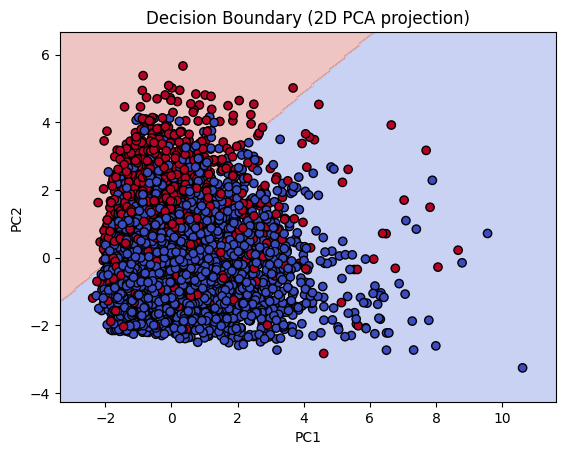

In [34]:
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(x_test_2d[:,0], x_test_2d[:,1], c=y_test, cmap=plt.cm.coolwarm, edgecolor='k')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Decision Boundary (2D PCA projection)')
plt.show()

## Logistic Regression

In [35]:
lg = LogisticRegression(max_iter=1000)
lg.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

In [36]:
y_pred = lg.predict(x_test)

In [37]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.860684952735162

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.95      0.91      5038
           1       0.75      0.55      0.63      1415

    accuracy                           0.86      6453
   macro avg       0.82      0.75      0.77      6453
weighted avg       0.85      0.86      0.85      6453



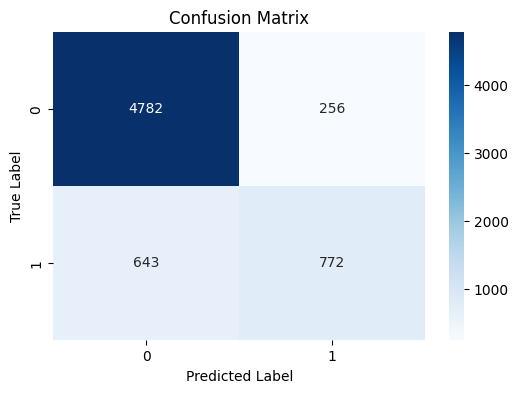

In [38]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [39]:
Z = (lg.predict(grid_orig) > 0.5).astype(int)
Z = Z.reshape(xx.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


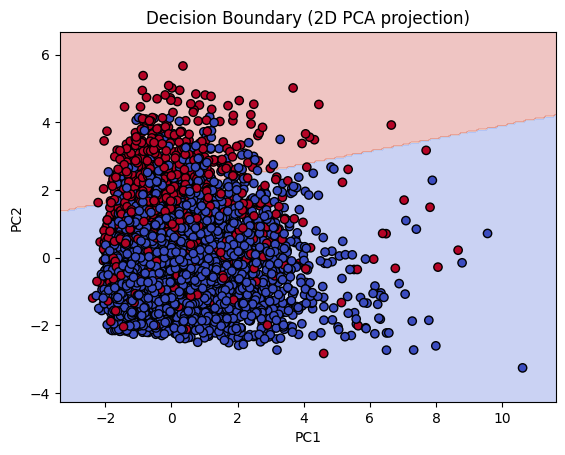

In [40]:
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(x_test_2d[:,0], x_test_2d[:,1], c=y_test, cmap=plt.cm.coolwarm, edgecolor='k')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Decision Boundary (2D PCA projection)')
plt.show()

## Random Forest

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

rf.fit(x_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [ ]:
y_pred = rf.predict(x_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.936618626995196

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.99      0.96      5038
           1       0.97      0.74      0.84      1415

    accuracy                           0.94      6453
   macro avg       0.95      0.86      0.90      6453
weighted avg       0.94      0.94      0.93      6453



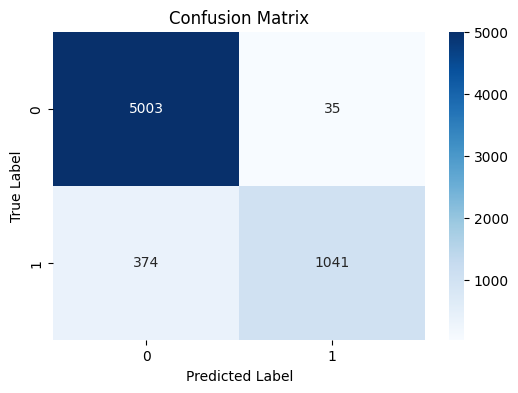

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
Z = (rf.predict(grid_orig) > 0.5).astype(int)
Z = Z.reshape(xx.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


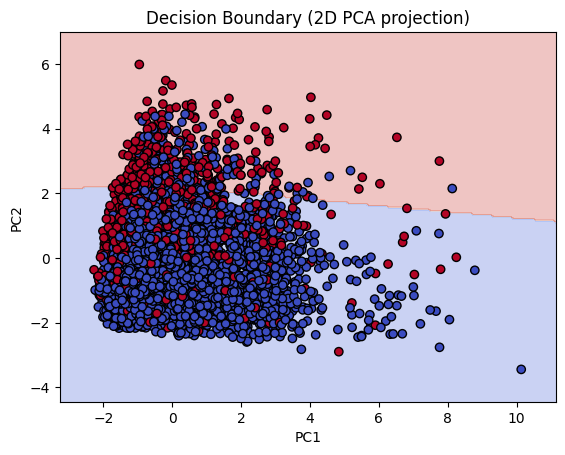

In [ ]:
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(x_test_2d[:,0], x_test_2d[:,1], c=y_test, cmap=plt.cm.coolwarm, edgecolor='k')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Decision Boundary (2D PCA projection)')
plt.show()

## ⚖️ Addressing Class Imbalance

Since our target class `loan_status` is highly imbalanced (~22% defaults), standard models can be heavily biased towards predicting non-defaults. To improve default identification, we apply:
 **XGBoost with Cost-Sensitive Learning (`scale_pos_weight`)**


In [45]:
from xgboost import XGBClassifier

# Compute scale factor: ratio of majority class to minority class
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count

print(f"Negative (0) count: {neg_count}")
print(f"Positive (1) count: {pos_count}")
print(f"Calculated scale_pos_weight: {scale_weight:.2f}")

# 1. Train cost-sensitive XGBoost
xgb_balanced = XGBClassifier(
    n_estimators=200,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric='logloss'
)
xgb_balanced.fit(x_train, y_train)

y_pred_xgb = xgb_balanced.predict(x_test)
print("\n--- XGBoost with Class Weighting Results ---")
print(classification_report(y_test, y_pred_xgb))

Negative (0) count: 20150
Positive (1) count: 5659
Calculated scale_pos_weight: 3.56

--- XGBoost with Class Weighting Results ---
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      5038
           1       0.83      0.81      0.82      1415

    accuracy                           0.92      6453
   macro avg       0.89      0.88      0.89      6453
weighted avg       0.92      0.92      0.92      6453



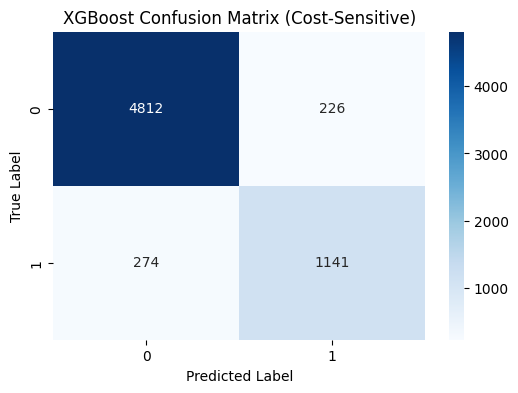

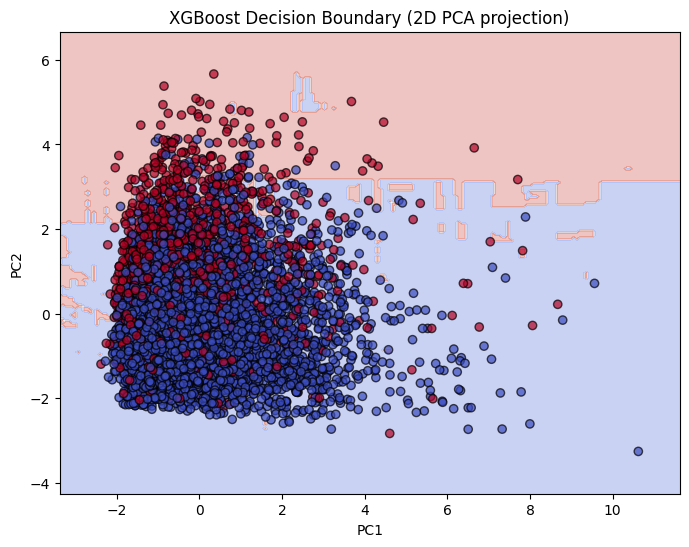

In [47]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues')
plt.title("XGBoost Confusion Matrix (Cost-Sensitive)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Z_xgb = (xgb_balanced.predict(grid_orig) > 0.5).astype(int)
Z_xgb = Z_xgb.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z_xgb, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(x_test_2d[:, 0], x_test_2d[:, 1], c=y_test, cmap=plt.cm.coolwarm, edgecolor='k', alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('XGBoost Decision Boundary (2D PCA projection)')
plt.show()

## 🏁 Final Conclusion

Based on our comprehensive pipeline evaluating classical Machine Learning models alongside dedicated class-imbalance techniques on the Credit Risk Dataset (6,453 test applicants), we observe the following performance metrics:

### 📊 Comparative Model Performance Summary

1. **Logistic Regression:** ~86.1% accuracy. A solid parametric model, though limited in capturing complex non-linear structures in the credit data, resulting in a lower recall (55%) for high-risk defaults.
2. **Random Forest (Baseline):** **~93.66% accuracy**. While yielding the highest raw accuracy and strong overall performance, this standard classifier suffers from a drop in recall for default predictions (~74% recall) due to class imbalance.
3. **XGBoost (Cost-Sensitive `scale_pos_weight`):** **~92.0% accuracy**. By penalizing minority class misclassifications, it substantially boosts default detection (**Recall: 81%, F1-Score: 82%**), yielding a highly robust credit risk model.

### 🏆 Key Takeaways & Recommendations
* **Addressing Imbalance is Critical:** Standard models trained on imbalanced credit data can achieve high overall accuracy but miss over 25% of actual defaults. Integrating cost-sensitive learning (XGBoost) dramatically improves default detection.
* **Production Deployment Choice:** For risk-averse lending, **XGBoost with weighted losses** is highly recommended as it catches the highest number of potential defaults (81% recall) while maintaining a high overall accuracy (92.0%).